# RBF SVM for Missense Variant Pathogenicity

Group 8, Rishitha Gogineni

This notebook trains my RBF SVM on the shared dataset and compares three feature sets under two validation schemes.

1. Set A: 6 conservation features.
2. Set B: conservation and population frequency, 15 features.
3. Set D: all 28 features, adding the amino acid features.

Standard stratified validation shows normal performance. Gene disjoint validation keeps all variants of a gene in the same fold, so the model is always tested on genes it has never seen.

The two hypotheses from my proposal:

1. H1: set B performs better than set A, especially on PR AUC and MCC.
2. H2: set D performs better than or as well as set A under gene disjoint validation.

## 1. Setup

This repository copy is stored in notebooks/ and searches its parent folders for the project root. The prepared data, feature configuration, and shared fold assignments are in data/processed/. Results are saved in results/rbf_svm/.

C controls how strongly the SVM penalizes mistakes, and gamma controls how far the influence of each training point reaches. The sets have different numbers of features, so gamma is written as a factor divided by the number of features. This way the same grid means the same thing for A, B and D.

To keep tuning fast, C and gamma are chosen on a sample of 10,000 rows from each training fold. The final model is then trained on the full training fold. Set `QUICK_TEST = True` to run one fold of each setting as a check.

In [1]:
import json
import os
import pickle
import platform
import resource
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from joblib import Parallel, delayed
from scipy.stats import wilcoxon
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.kernel_approximation import Nystroem
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_recall_curve,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedGroupKFold,
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

SEARCH_DIRS = (Path.cwd(), *Path.cwd().parents)
DATA_DIR = next((p for p in SEARCH_DIRS if (p / "data/processed" / "fold_assignments.csv").is_file() and (p / "data/processed" / "clinvar_expanded_model_features.csv").is_file()), Path.cwd())
PREP_DIR = DATA_DIR / "data/processed"
RESULTS_DIR = DATA_DIR / "results/rbf_svm"
FIG_DIR = RESULTS_DIR / "figures" / "evaluation_plots"
(RESULTS_DIR / "folds").mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
N_FOLDS = 5
N_REPEATS = 3
INNER_FOLDS = 3

C_VALUES = [0.01, 0.1, 1, 10]
GAMMA_FACTORS = [0.0625, 0.25, 1, 4]  # divided by the number of features to get gamma
TUNE_ROWS = 10000
THRESHOLD = 0.5  # shared team rule: pathogenic when p_pathogenic is at least 0.5
N_JOBS = min(6, os.cpu_count())

QUICK_TEST = False

SCHEMES = ["standard", "gene_disjoint"]
SETS = ["A", "B", "D"]
ORDER = [(s, n) for s in SCHEMES for n in SETS]
SCHEME_NAMES = {"standard": "Standard", "gene_disjoint": "Gene disjoint"}
METRIC_NAMES = {"roc_auc": "ROC AUC", "pr_auc": "PR AUC", "mcc": "MCC"}

print("Python:", platform.python_version())
print("scikit-learn:", sklearn.__version__)
print("CPU cores:", os.cpu_count(), "| parallel jobs:", N_JOBS)

Python: 3.11.16
scikit-learn: 1.9.0
CPU cores: 8 | parallel jobs: 6


## 2. Load the data

In [2]:
df = pd.read_csv(PREP_DIR / "clinvar_expanded_model_features.csv")
with open(PREP_DIR / "feature_config.json") as f:
    config = json.load(f)

feature_sets = {name: config["feature_sets"][name] for name in SETS}
y = df["label"].to_numpy()
genes = df["GeneSymbol"].to_numpy()

print("Variants:", len(df))
print("Genes:", df["GeneSymbol"].nunique())
print("Pathogenic share:", f"{y.mean():.2%}")
for name, cols in feature_sets.items():
    print(f"Set {name}: {len(cols)} features")

Variants: 46012
Genes: 2105
Pathogenic share: 30.42%
Set A: 6 features
Set B: 15 features
Set D: 28 features


## 3. Load the shared folds

The team agreed to use one fold file, `fold_assignments.csv`, so that every model is trained and tested on exactly the same variants. It has standard and gene disjoint folds, 3 repeats (numbered 0 to 2) and 5 folds each (numbered 0 to 4). I do not create any new splits. The same folds are used for A, B and D, which also allows paired tests later.

The cell checks that every variant has a fold and that no gene is split across gene disjoint folds.

In [3]:
fold_long = pd.read_csv(PREP_DIR / "fold_assignments.csv")
fold_wide = fold_long.pivot(index="VariationID", columns=["validation", "repeat"], values="test_fold")
fold_wide.columns = [f"{v}_r{r}" for v, r in fold_wide.columns]

folds = df[["VariationID", "GeneSymbol", "label"]].merge(
    fold_wide.reset_index(), on="VariationID", how="left"
)
fold_cols = [f"{s}_r{r}" for s in SCHEMES for r in range(N_REPEATS)]
if folds[fold_cols].isna().any().any():
    raise ValueError("Some variants have no fold in fold_assignments.csv")
folds[fold_cols] = folds[fold_cols].astype(int)

for r in range(N_REPEATS):
    if folds.groupby("GeneSymbol")[f"gene_disjoint_r{r}"].nunique().max() > 1:
        raise ValueError(f"A gene is split across gene disjoint folds in repeat {r}")

print("Variants with folds:", len(folds))
fold_summary = pd.concat({
    SCHEME_NAMES[s]: folds.groupby(f"{s}_r0")["label"].agg(variants="size", pathogenic_share="mean")
    for s in SCHEMES
}, axis=1)
fold_summary.index.name = "fold (repeat 0)"
display(fold_summary.round(3))

Variants with folds: 46012


Standard                  Gene disjoint                 
                variants pathogenic_share      variants pathogenic_share
fold (repeat 0)                                                         
0                   9203            0.304          9092            0.338
1                   9203            0.304          9684            0.247
2                   9202            0.304          8970            0.346
3                   9202            0.304          9197            0.267
4                   9202            0.304          9069            0.328

## 4. Model, metrics and one fold

Each model is a pipeline of median imputation, standard scaling and the RBF SVM. Since these steps are inside the pipeline, they are fit on training data only, in every fold and every tuning split. Class weights are balanced because only about 30% of the variants are pathogenic.

C and gamma are tuned with a 4 by 4 grid and 3 inner folds, scored by PR AUC because it focuses on the pathogenic class. In gene disjoint runs the inner folds are also split by gene.

An SVM gives a decision score, not a probability. The team format needs a probability (`p_pathogenic`), so I use Platt scaling. The tuned SVM is trained on 3 inner folds of the training data, and a small logistic regression learns how its decision scores on the held out part map to probabilities. In gene disjoint runs these inner folds are also split by gene. The test fold is never used. A variant is labeled pathogenic when `p_pathogenic` is 0.5 or more, the threshold shared by the team. The raw decision score is kept for the support vector and decision score analysis.

For each fold, `run_fold` saves the metrics, the chosen C and gamma, support vector counts, decision score summaries, run times, memory use and the test predictions.

In [4]:
def make_model():
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("svm", SVC(kernel="rbf", class_weight="balanced", cache_size=500)),
    ])


def get_metrics(y_true, score, pred):
    return {
        "roc_auc": roc_auc_score(y_true, score),
        "pr_auc": average_precision_score(y_true, score),
        "mcc": matthews_corrcoef(y_true, pred),
        "f1": f1_score(y_true, pred),
        "sensitivity": recall_score(y_true, pred),
        "specificity": recall_score(y_true, pred, pos_label=0),
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
    }


def peak_memory_mb():
    peak = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    # macOS reports bytes, Linux reports kilobytes
    return peak / 1024**2 if platform.system() == "Darwin" else peak / 1024


def fold_file(scheme, set_name, repeat, fold):
    return RESULTS_DIR / "folds" / f"{scheme}_{set_name}_r{repeat}_f{fold}.pkl"

In [5]:
def run_fold(scheme, set_name, repeat, fold):
    out_file = fold_file(scheme, set_name, repeat, fold)
    if out_file.exists():
        return

    cols = feature_sets[set_name]
    X = df[cols].to_numpy()
    is_test = folds[f"{scheme}_r{repeat}"].to_numpy() == fold
    train_idx, test_idx = np.where(~is_test)[0], np.where(is_test)[0]

    X_train, y_train, g_train = X[train_idx], y[train_idx], genes[train_idx]
    X_test, y_test = X[test_idx], y[test_idx]

    # Tuning sample comes from the training fold only
    tune_idx = np.arange(len(train_idx))
    if TUNE_ROWS and TUNE_ROWS < len(train_idx):
        tune_idx, _ = train_test_split(
            tune_idx, train_size=TUNE_ROWS, stratify=y_train, random_state=SEED
        )
    X_tune, y_tune, g_tune = X_train[tune_idx], y_train[tune_idx], g_train[tune_idx]

    if scheme == "gene_disjoint":
        inner_cv = StratifiedGroupKFold(INNER_FOLDS, shuffle=True, random_state=SEED)
        inner_splits = list(inner_cv.split(X_tune, y_tune, groups=g_tune))
    else:
        inner_cv = StratifiedKFold(INNER_FOLDS, shuffle=True, random_state=SEED)
        inner_splits = list(inner_cv.split(X_tune, y_tune))

    grid = {
        "svm__C": C_VALUES,
        "svm__gamma": [g / len(cols) for g in GAMMA_FACTORS],
    }
    search = GridSearchCV(
        make_model(), grid, scoring="average_precision", cv=inner_splits, n_jobs=1
    )

    start = time.time()
    search.fit(X_tune, y_tune)
    tune_time = time.time() - start

    if scheme == "gene_disjoint":
        cal_cv = StratifiedGroupKFold(INNER_FOLDS, shuffle=True, random_state=SEED)
        cal_splits = list(cal_cv.split(X_train, y_train, groups=g_train))
    else:
        cal_cv = StratifiedKFold(INNER_FOLDS, shuffle=True, random_state=SEED)
        cal_splits = list(cal_cv.split(X_train, y_train))

    # Platt scaling: out of fold decision scores on the training data are mapped to probabilities
    start = time.time()
    oof_score = cross_val_predict(
        make_model().set_params(**search.best_params_), X_train, y_train,
        cv=cal_splits, method="decision_function",
    )
    platt = LogisticRegression(C=1e6).fit(oof_score.reshape(-1, 1), y_train)
    calib_time = time.time() - start

    model = make_model().set_params(**search.best_params_)
    start = time.time()
    model.fit(X_train, y_train)
    fit_time = time.time() - start

    start = time.time()
    score = model.decision_function(X_test)
    p_path = platt.predict_proba(score.reshape(-1, 1))[:, 1]
    predict_time = time.time() - start
    pred = (p_path >= THRESHOLD).astype(int)

    sv_benign, sv_path = model.named_steps["svm"].n_support_
    n_benign, n_path = (y_train == 0).sum(), (y_train == 1).sum()

    row = {
        "scheme": scheme,
        "set": set_name,
        "repeat": repeat,
        "fold": fold,
        "n_train": len(train_idx),
        "n_test": len(test_idx),
        "best_C": search.best_params_["svm__C"],
        "best_gamma": search.best_params_["svm__gamma"],
        "best_gamma_factor": round(search.best_params_["svm__gamma"] * len(cols), 4),
        "inner_pr_auc": search.best_score_,
        **get_metrics(y_test, p_path, pred),
        "sv_benign": sv_benign,
        "sv_pathogenic": sv_path,
        "sv_benign_pct": 100 * sv_benign / n_benign,
        "sv_pathogenic_pct": 100 * sv_path / n_path,
        "sv_total_pct": 100 * (sv_benign + sv_path) / len(train_idx),
        "median_score_benign": np.median(score[y_test == 0]),
        "median_score_pathogenic": np.median(score[y_test == 1]),
        "in_margin_pct": 100 * np.mean(np.abs(score) < 1),
        "tune_time": tune_time,
        "calib_time": calib_time,
        "fit_time": fit_time,
        "predict_time": predict_time,
        "model_mb": len(pickle.dumps(model)) / 1024**2,
        "peak_mem_mb": peak_memory_mb(),
    }

    preds = pd.DataFrame({
        "VariationID": df["VariationID"].to_numpy()[test_idx],
        "label": y_test,
        "decision_score": score,
        "p_pathogenic": p_path,
        "pred_label": pred,
    })
    grid_scores = pd.DataFrame(search.cv_results_)[
        ["param_svm__C", "param_svm__gamma", "mean_test_score"]
    ]

    with open(out_file, "wb") as f:
        pickle.dump({"row": row, "preds": preds, "grid": grid_scores}, f)

## 5. Run all folds

There are 90 runs in total: 2 schemes, 3 feature sets, 3 repeats and 5 folds. They run in parallel threads and each finished run is saved in `results/rbf_svm/folds`. If the notebook stops, running this cell again skips the runs that are already done, including the ones from a quick test.

In [6]:
tasks = [
    (scheme, set_name, r, k)
    for scheme in SCHEMES
    for set_name in SETS
    for r in range(N_REPEATS)
    for k in range(N_FOLDS)
]
if QUICK_TEST:
    tasks = [t for t in tasks if t[2] == 0 and t[3] == 0]

done = sum(fold_file(*t).exists() for t in tasks)
print(f"Runs: {len(tasks)}, already finished: {done}")

start = time.time()
# SVM training releases the Python lock, so threads run in parallel
Parallel(n_jobs=N_JOBS, backend="threading", verbose=10)(delayed(run_fold)(*t) for t in tasks)
print(f"Finished in {(time.time() - start) / 60:.1f} minutes")

Runs: 90, already finished: 6
[Parallel(n_jobs=6)]: Using backend ThreadingBackend with 6 concurrent workers.
[Parallel(n_jobs=6)]: Done   1 tasks      | elapsed:    0.0s
[Parallel(n_jobs=6)]: Done   6 tasks      | elapsed:  5.3min
[Parallel(n_jobs=6)]: Done  13 tasks      | elapsed: 11.0min
[Parallel(n_jobs=6)]: Done  20 tasks      | elapsed: 16.2min
[Parallel(n_jobs=6)]: Done  29 tasks      | elapsed: 27.2min
[Parallel(n_jobs=6)]: Done  38 tasks      | elapsed: 32.9min
[Parallel(n_jobs=6)]: Done  49 tasks      | elapsed: 43.3min
[Parallel(n_jobs=6)]: Done  60 tasks      | elapsed: 61.5min
[Parallel(n_jobs=6)]: Done  73 tasks      | elapsed: 75.2min
[Parallel(n_jobs=6)]: Done  90 out of  90 | elapsed: 93.7min finished
Finished in 93.7 minutes


## 6. Collect the results

All saved runs are combined into one results table and one predictions table, and both are saved as CSV files.

In [7]:
rows, pred_list, grid_list = [], [], []

for path in sorted((RESULTS_DIR / "folds").glob("*.pkl")):
    with open(path, "rb") as f:
        saved = pickle.load(f)
    row = saved["row"]
    info = {k: row[k] for k in ["scheme", "set", "repeat", "fold"]}
    rows.append(row)
    pred_list.append(saved["preds"].assign(**info))
    grid_list.append(saved["grid"].assign(**info))

results = pd.DataFrame(rows).sort_values(["scheme", "set", "repeat", "fold"]).reset_index(drop=True)
preds = pd.concat(pred_list, ignore_index=True)
grid_scores = pd.concat(grid_list, ignore_index=True)

# Accuracy comes from the saved predictions, so older runs have it too
keys = ["scheme", "set", "repeat", "fold"]
acc_rows = [
    {
        **dict(zip(keys, key)),
        "accuracy": accuracy_score(part["label"], part["pred_label"]),
        "balanced_accuracy": balanced_accuracy_score(part["label"], part["pred_label"]),
    }
    for key, part in preds.groupby(keys)
]
results = results.drop(columns=["accuracy", "balanced_accuracy"], errors="ignore").merge(
    pd.DataFrame(acc_rows), on=keys
)

results.to_csv(RESULTS_DIR / "svm_fold_results.csv", index=False)

# The predictions file is large, so it is written once after all runs finish
pred_file = RESULTS_DIR / "svm_predictions.csv"
if len(results) == 90 and not pred_file.exists():
    preds.to_csv(pred_file, index=False)

# Predictions in the format shared by the team
shared_file = RESULTS_DIR / "predictions_rbf_svm.csv"
shared_cols = ["model", "feature_set", "validation", "repeat", "fold",
               "VariationID", "label", "p_pathogenic", "pred_label"]
if len(results) == 90 and not shared_file.exists():
    shared = preds.rename(columns={"scheme": "validation", "set": "feature_set"}).assign(model="RBF_SVM")
    shared[shared_cols].to_csv(shared_file, index=False)

print("Runs collected:", len(results), "of 90")
if len(results) < 90:
    print("Some runs are missing, so the tables below are partial.")

Runs collected: 90 of 90


In [8]:
def mean_sd_table(data, cols, digits=3):
    grouped = data.groupby(["scheme", "set"])[cols]
    means = grouped.mean().reindex(ORDER).dropna(how="all")
    sds = grouped.std().reindex(means.index)
    text = means.apply(lambda c: c.map(f"{{:.{digits}f}}".format))
    text += " (" + sds.apply(lambda c: c.map(f"{{:.{digits}f}}".format)) + ")"
    return text.rename(index=SCHEME_NAMES, level=0)

## 7. Performance of A, B and D

Mean over the 15 test folds, with the standard deviation in brackets.

Accuracy is shown for completeness, but it is not a good guide here. About 70% of the variants are benign, so a model that always predicts benign already gets about 70% accuracy. Balanced accuracy averages sensitivity and specificity, so that model would only get 50%. ROC AUC, PR AUC and MCC remain the main metrics.

In [9]:
metric_cols = [
    "roc_auc", "pr_auc", "mcc", "f1", "sensitivity", "specificity", "accuracy", "balanced_accuracy"
]
perf_table = mean_sd_table(results, metric_cols)
perf_table.to_csv(RESULTS_DIR / "table_performance.csv")
display(perf_table)

print(f"Accuracy when always predicting benign: {1 - y.mean():.3f}")

roc_auc         pr_auc            mcc             f1    sensitivity    specificity       accuracy balanced_accuracy
scheme        set                                                                                                                           
Standard      A    0.789 (0.006)  0.588 (0.009)  0.439 (0.012)  0.611 (0.012)  0.618 (0.031)  0.823 (0.017)  0.761 (0.006)     0.720 (0.008)
              B    0.860 (0.003)  0.713 (0.007)  0.516 (0.009)  0.659 (0.008)  0.641 (0.016)  0.867 (0.007)  0.798 (0.003)     0.754 (0.006)
              D    0.897 (0.003)  0.782 (0.006)  0.603 (0.011)  0.724 (0.008)  0.728 (0.016)  0.877 (0.007)  0.831 (0.004)     0.802 (0.007)
Gene disjoint A    0.789 (0.011)  0.584 (0.045)  0.429 (0.022)  0.599 (0.025)  0.598 (0.048)  0.830 (0.028)  0.758 (0.012)     0.714 (0.014)
              B    0.860 (0.009)  0.710 (0.043)  0.514 (0.021)  0.656 (0.020)  0.640 (0.034)  0.866 (0.025)  0.796 (0.008)     0.753 (0.009)
              D    0.896 (0.007)  0.778 (0.034)  0.597 (0.017)  0.718 (0.019)  0.723 (0.027)  0.876 (0.019)  0.828 (0.007)     0.799 (0.007)

Accuracy when always predicting benign: 0.696


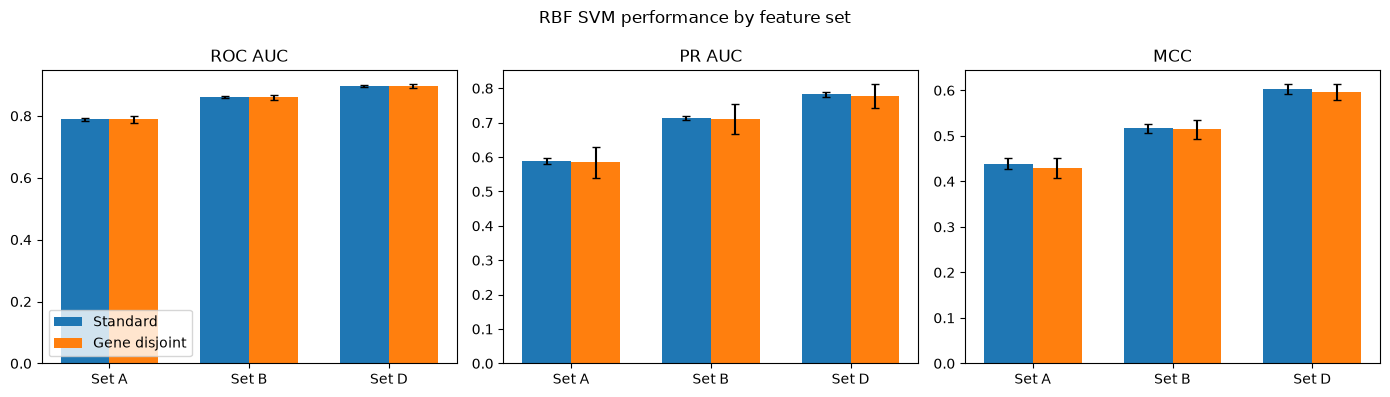

In [10]:
means = results.groupby(["scheme", "set"])[list(METRIC_NAMES)].mean()
sds = results.groupby(["scheme", "set"])[list(METRIC_NAMES)].std()
x = np.arange(len(SETS))
width = 0.35

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, METRIC_NAMES):
    for i, scheme in enumerate(SCHEMES):
        if scheme not in means.index.get_level_values(0):
            continue
        m = means.loc[scheme].reindex(SETS)[metric]
        s = sds.loc[scheme].reindex(SETS)[metric]
        ax.bar(x + (i - 0.5) * width, m, width, yerr=s, capsize=3, label=SCHEME_NAMES[scheme])
    ax.set_xticks(x, [f"Set {n}" for n in SETS])
    ax.set_title(METRIC_NAMES[metric])
axes[0].legend()
plt.suptitle("RBF SVM performance by feature set")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_performance.png", dpi=200)
plt.show()

## 8. ROC and PR curves

These curves use repeat 0, where every variant is tested exactly once, so the predictions from the five test folds are pooled. The dashed lines show a model that guesses at random.

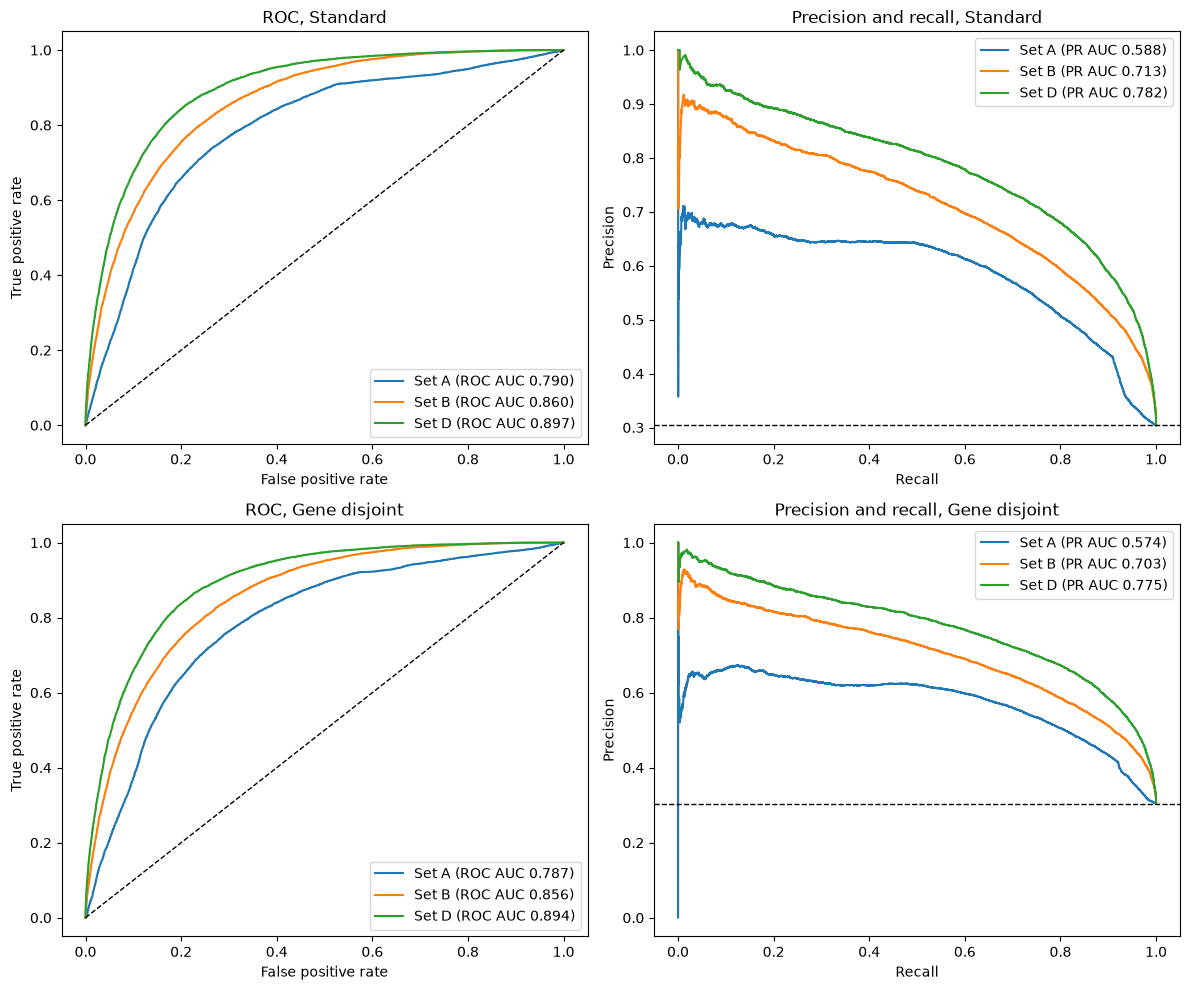

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for i, scheme in enumerate(SCHEMES):
    roc_ax, pr_ax = axes[i]
    for set_name in SETS:
        part = preds.query("scheme == @scheme and set == @set_name and repeat == 0")
        if part.empty:
            continue
        fpr, tpr, _ = roc_curve(part["label"], part["p_pathogenic"])
        precision, recall, _ = precision_recall_curve(part["label"], part["p_pathogenic"])
        roc_auc = roc_auc_score(part["label"], part["p_pathogenic"])
        pr_auc = average_precision_score(part["label"], part["p_pathogenic"])
        roc_ax.plot(fpr, tpr, label=f"Set {set_name} (ROC AUC {roc_auc:.3f})")
        pr_ax.plot(recall, precision, label=f"Set {set_name} (PR AUC {pr_auc:.3f})")
    roc_ax.plot([0, 1], [0, 1], "k--", linewidth=1)
    pr_ax.axhline(y.mean(), color="black", linestyle="--", linewidth=1)
    roc_ax.set(xlabel="False positive rate", ylabel="True positive rate", title=f"ROC, {SCHEME_NAMES[scheme]}")
    pr_ax.set(xlabel="Recall", ylabel="Precision", title=f"Precision and recall, {SCHEME_NAMES[scheme]}")
    roc_ax.legend(loc="lower right")
    pr_ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_roc_pr_curves.png", dpi=200)
plt.show()

## 9. Confusion matrix

Results for set D in repeat 0, where a variant is labeled pathogenic when `p_pathogenic` is 0.5 or more. Each row is the true class, and the percentages show how the variants of that class were predicted.

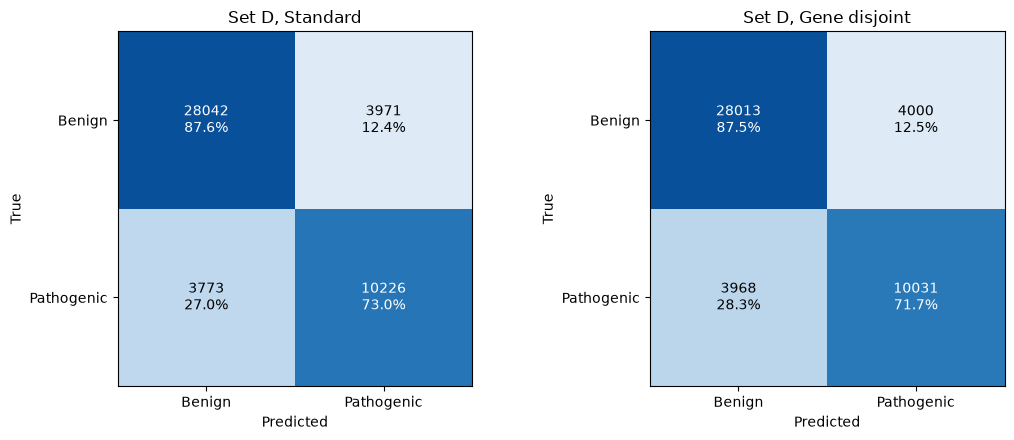

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, scheme in zip(axes, SCHEMES):
    part = preds.query("scheme == @scheme and set == 'D' and repeat == 0")
    if part.empty:
        ax.set_visible(False)
        continue
    cm = confusion_matrix(part["label"], part["pred_label"])
    row_pct = 100 * cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(row_pct, cmap="Blues", vmin=0, vmax=100)
    for r in range(2):
        for c in range(2):
            color = "white" if row_pct[r, c] > 50 else "black"
            ax.text(c, r, f"{cm[r, c]}\n{row_pct[r, c]:.1f}%", ha="center", va="center", color=color)
    ax.set_xticks([0, 1], ["Benign", "Pathogenic"])
    ax.set_yticks([0, 1], ["Benign", "Pathogenic"])
    ax.set(xlabel="Predicted", ylabel="True", title=f"Set D, {SCHEME_NAMES[scheme]}")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_confusion_matrix.png", dpi=200)
plt.show()

## 10. Hypothesis tests

All sets were tested on the same 15 folds, so I compare them fold by fold. I use the Wilcoxon signed rank test because it does not assume the differences are normally distributed. The folds share training data, so the p values are a rough guide rather than exact.

H1 is the B versus A comparison. H2 is the D versus A comparison under gene disjoint validation. D versus B shows what the amino acid features add on top of B.

In [13]:
def compare_sets(scheme, set_1, set_2, metric):
    wide = results.query("scheme == @scheme").pivot_table(
        index=["repeat", "fold"], columns="set", values=metric
    )
    if set_1 not in wide or set_2 not in wide:
        return None
    pair = wide[[set_1, set_2]].dropna()
    diff = pair[set_2] - pair[set_1]
    p = wilcoxon(pair[set_2], pair[set_1]).pvalue if len(diff) >= 5 else np.nan
    return {
        "scheme": SCHEME_NAMES[scheme],
        "comparison": f"{set_2} vs {set_1}",
        "metric": METRIC_NAMES[metric],
        "mean_diff": round(diff.mean(), 4),
        "folds_improved": f"{(diff > 0).sum()} of {len(diff)}",
        "p_value": p,
    }


tests = [
    compare_sets(scheme, set_1, set_2, metric)
    for scheme in SCHEMES
    for set_1, set_2 in [("A", "B"), ("A", "D"), ("B", "D")]
    for metric in METRIC_NAMES
]
test_table = pd.DataFrame([t for t in tests if t])
test_table.to_csv(RESULTS_DIR / "table_hypothesis_tests.csv", index=False)
display(test_table)

,scheme,comparison,metric,mean_diff,folds_improved,p_value
0,Standard,B vs A,ROC AUC,0.0716,15 of 15,0.000061
1,Standard,B vs A,PR AUC,0.1253,15 of 15,0.000061
2,Standard,B vs A,MCC,0.0777,15 of 15,0.000061
3,Standard,D vs A,ROC AUC,0.1085,15 of 15,0.000061
4,Standard,D vs A,PR AUC,0.1943,15 of 15,0.000061
5,Standard,D vs A,MCC,0.1644,15 of 15,0.000061
6,Standard,D vs B,ROC AUC,0.0369,15 of 15,0.000061
7,Standard,D vs B,PR AUC,0.0689,15 of 15,0.000061
8,Standard,D vs B,MCC,0.0867,15 of 15,0.000061
9,Gene disjoint,B vs A,ROC AUC,0.0708,15 of 15,0.000061


## 11. Standard versus gene disjoint

The drop from standard to gene disjoint validation shows how much a normal split overestimates performance on new genes. A bigger drop means the model gains more from having seen other variants of the same gene.

,roc_auc,pr_auc,mcc
set,,,
A,-0.0003,0.0035,0.0098
B,0.0005,0.0030,0.0022
D,0.0007,0.0040,0.0065


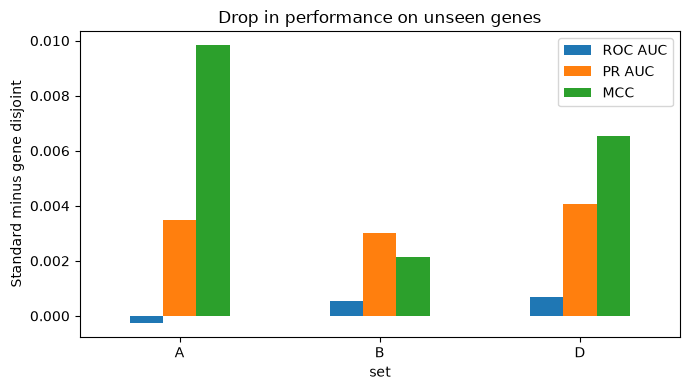

In [14]:
if set(SCHEMES) <= set(means.index.get_level_values(0)):
    gap = (means.loc["standard"] - means.loc["gene_disjoint"]).reindex(SETS)
    gap.to_csv(RESULTS_DIR / "table_validation_gap.csv")
    display(gap.round(4))

    gap.plot.bar(figsize=(7, 4), rot=0)
    plt.ylabel("Standard minus gene disjoint")
    plt.title("Drop in performance on unseen genes")
    plt.legend([METRIC_NAMES[m] for m in gap.columns])
    plt.tight_layout()
    plt.savefig(FIG_DIR / "fig_validation_gap.png", dpi=200)
    plt.show()

## 12. Support vectors

Support vectors are the training variants that define the decision boundary. A smaller share usually means a cleaner boundary. A large share means many variants sit close to the boundary or on the wrong side of it.

In [15]:
sv_cols = ["sv_benign", "sv_pathogenic", "sv_benign_pct", "sv_pathogenic_pct", "sv_total_pct"]
sv_table = mean_sd_table(results, sv_cols, digits=1)
sv_table.to_csv(RESULTS_DIR / "table_support_vectors.csv")
display(sv_table)

sv_benign   sv_pathogenic sv_benign_pct sv_pathogenic_pct sv_total_pct
scheme        set                                                                              
Standard      A    14952.5 (452.1)  6439.7 (277.0)    58.4 (1.8)        57.5 (2.5)   58.1 (2.0)
              B    13513.5 (353.9)  5910.5 (154.7)    52.8 (1.4)        52.8 (1.4)   52.8 (1.4)
              D    10978.6 (229.6)   4835.7 (81.6)    42.9 (0.9)        43.2 (0.7)   43.0 (0.8)
Gene disjoint A    15279.1 (739.3)  6610.0 (341.3)    59.7 (2.6)        59.1 (3.3)   59.5 (2.8)
              B    13566.1 (503.1)  5931.9 (194.3)    53.0 (1.5)        53.0 (1.5)   53.0 (1.5)
              D    10971.7 (428.7)  4829.8 (140.6)    42.8 (1.1)        43.1 (0.9)   42.9 (1.0)

## 13. Decision scores

The decision score is the signed distance from the boundary, where positive means pathogenic. I compare the median score of each class and the share of test variants inside the margin, where the score is between minus 1 and 1.

The histograms use repeat 0, where every variant is tested exactly once.

In [16]:
score_cols = ["median_score_benign", "median_score_pathogenic", "in_margin_pct"]
score_table = mean_sd_table(results, score_cols, digits=2)
score_table.to_csv(RESULTS_DIR / "table_decision_scores.csv")
display(score_table)

median_score_benign median_score_pathogenic in_margin_pct
scheme        set                                                          
Standard      A          -0.88 (0.13)             0.96 (0.04)  49.36 (2.15)
              B          -0.89 (0.06)             0.95 (0.03)  46.79 (1.88)
              D          -1.23 (0.03)             1.11 (0.02)  37.18 (1.05)
Gene disjoint A          -0.82 (0.14)             0.93 (0.06)  50.73 (3.13)
              B          -0.88 (0.17)             0.95 (0.05)  47.01 (2.97)
              D          -1.23 (0.10)             1.12 (0.04)  37.37 (1.45)

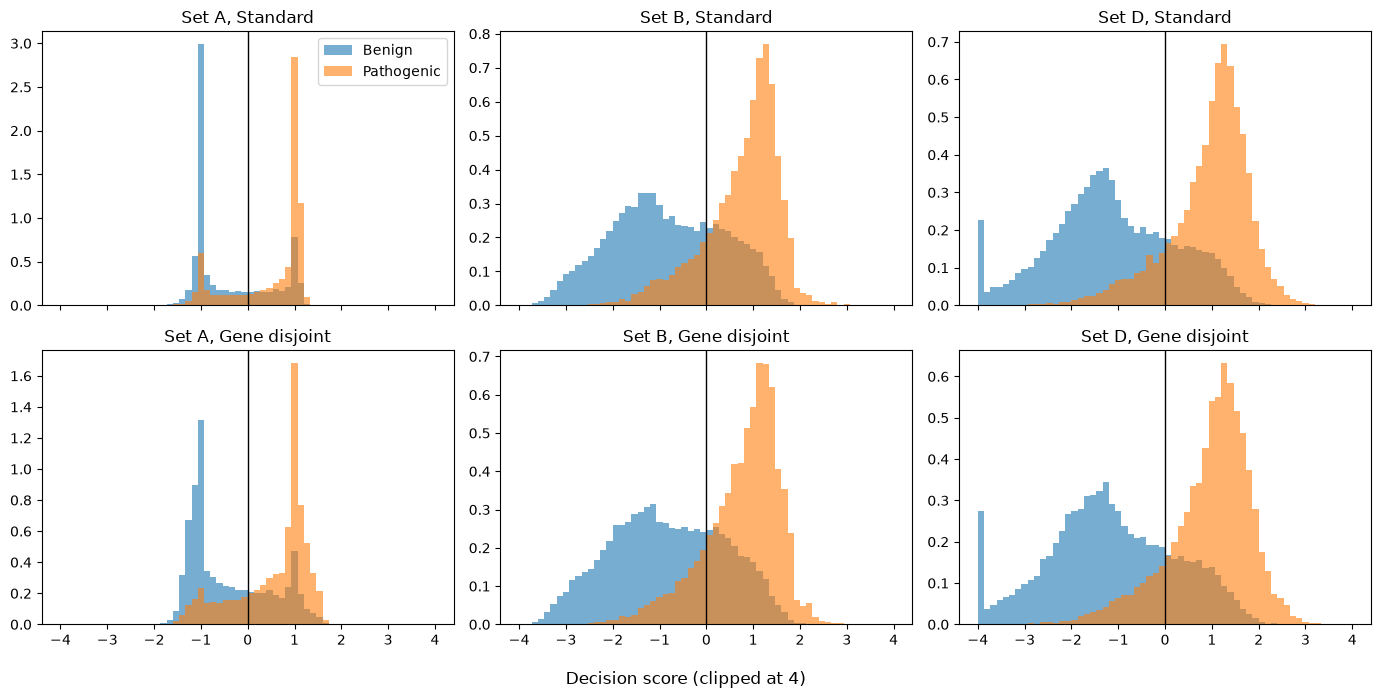

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True)
for i, scheme in enumerate(SCHEMES):
    for j, set_name in enumerate(SETS):
        ax = axes[i, j]
        part = preds.query("scheme == @scheme and set == @set_name and repeat == 0")
        if part.empty:
            ax.set_visible(False)
            continue
        bins = np.linspace(-4, 4, 61)
        ax.hist(part.loc[part["label"] == 0, "decision_score"].clip(-4, 4), bins=bins, alpha=0.6, density=True, label="Benign")
        ax.hist(part.loc[part["label"] == 1, "decision_score"].clip(-4, 4), bins=bins, alpha=0.6, density=True, label="Pathogenic")
        ax.axvline(0, color="black", linewidth=1)
        ax.set_title(f"Set {set_name}, {SCHEME_NAMES[scheme]}")
axes[0, 0].legend()
fig.supxlabel("Decision score (clipped at 4)")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_decision_scores.png", dpi=200)
plt.show()

## 14. Tuned C and gamma

How often each C and gamma factor was chosen, and the mean inner PR AUC for each grid point.

In [18]:
chosen = pd.crosstab(
    [results["scheme"].map(SCHEME_NAMES), results["set"]],
    [results["best_C"], results["best_gamma_factor"]],
)
chosen.columns.names = ["C", "gamma factor"]
display(chosen)

n_features = {name: len(cols) for name, cols in feature_sets.items()}
grid_scores["gamma_factor"] = (
    grid_scores["param_svm__gamma"].astype(float) * grid_scores["set"].map(n_features)
).round(4)
grid_mean = grid_scores.pivot_table(
    index=["scheme", "set", "param_svm__C"], columns="gamma_factor", values="mean_test_score"
)
display(grid_mean.round(3))

C                  0.01   0.10                 1.00                 10.00       
gamma factor      0.2500 0.0625 0.2500 4.0000 0.0625 0.2500 1.0000 0.0625 0.2500
scheme        set                                                               
Gene disjoint A        2      4      2      1      1      0      5      0      0
              B        0     11      0      0      3      0      0      1      0
              D        0      0      0      0      0      0      0     10      5
Standard      A        0      1      1      0      4      0      9      0      0
              B        0      9      0      0      6      0      0      0      0
              D        0      0      0      0      0      2      0      8      5

gamma_factor                    0.0625  0.2500  1.0000  4.0000
scheme        set param_svm__C                                
gene_disjoint A   0.01           0.583   0.591   0.587   0.580
                  0.10           0.592   0.591   0.586   0.586
                  1.00           0.592   0.584   0.592   0.571
                  10.00          0.585   0.584   0.584   0.555
              B   0.01           0.706   0.704   0.686   0.653
                  0.10           0.715   0.710   0.685   0.666
                  1.00           0.712   0.690   0.673   0.648
                  10.00          0.702   0.684   0.657   0.624
              D   0.01           0.741   0.750   0.733   0.676
                  0.10           0.759   0.765   0.752   0.717
                  1.00           0.767   0.771   0.756   0.715
                  10.00          0.772   0.770   0.740   0.678
standard      A   0.01           0.579   0.590   0.588   0.578
                  0.10           0.591   0.592   0.588   0.589
                  1.00           0.592   0.586   0.595   0.574
                  10.00          0.589   0.587   0.587   0.561
              B   0.01           0.706   0.705   0.687   0.655
                  0.10           0.715   0.711   0.689   0.669
                  1.00           0.714   0.693   0.674   0.658
                  10.00          0.704   0.684   0.661   0.633
              D   0.01           0.741   0.750   0.734   0.676
                  0.10           0.759   0.765   0.752   0.718
                  1.00           0.767   0.772   0.758   0.717
                  10.00          0.773   0.771   0.740   0.680

## 15. Validation curves

An SVM is not trained over epochs. It solves one convex optimization problem, so there is no loss curve like there is for a neural network. Validation curves and learning curves play the same role.

A validation curve changes one setting and compares the score on the training data with the score on the test fold. If the training score keeps rising while the test score falls, the model is overfitting.

I use set D on the five gene disjoint folds of repeat 0. To keep this quick, each model is trained on a 10,000 row sample of the training fold. C is changed with the gamma factor fixed at 0.25, and the gamma factor is changed with C fixed at 1.

In [19]:
CURVE_C = [0.01, 0.1, 1, 10, 100]
CURVE_GAMMA = [0.0625, 0.25, 1, 4, 16]
curve_cols = feature_sets["D"]


def curve_point(fold, C, gamma_factor):
    X = df[curve_cols].to_numpy()
    is_test = folds["gene_disjoint_r0"].to_numpy() == fold
    train_idx, test_idx = np.where(~is_test)[0], np.where(is_test)[0]
    train_idx, _ = train_test_split(
        train_idx, train_size=TUNE_ROWS, stratify=y[train_idx], random_state=SEED
    )

    model = make_model().set_params(svm__C=C, svm__gamma=gamma_factor / len(curve_cols))
    start = time.time()
    model.fit(X[train_idx], y[train_idx])
    fit_time = time.time() - start

    return {
        "fold": fold,
        "C": C,
        "gamma_factor": gamma_factor,
        "train_pr_auc": average_precision_score(y[train_idx], model.decision_function(X[train_idx])),
        "test_pr_auc": average_precision_score(y[test_idx], model.decision_function(X[test_idx])),
        "sv_pct": 100 * model.named_steps["svm"].n_support_.sum() / len(train_idx),
        "fit_time": fit_time,
    }


curve_file = RESULTS_DIR / "validation_curves.csv"
if curve_file.exists():
    curves = pd.read_csv(curve_file)
else:
    jobs = [(k, c, 0.25) for k in range(N_FOLDS) for c in CURVE_C]
    jobs += [(k, 1, g) for k in range(N_FOLDS) for g in CURVE_GAMMA if g != 0.25]
    curves = pd.DataFrame(
        Parallel(n_jobs=N_JOBS, backend="threading")(delayed(curve_point)(*j) for j in jobs)
    )
    curves.to_csv(curve_file, index=False)

display(curves.groupby(["C", "gamma_factor"]).mean().drop(columns="fold").round(3))

train_pr_auc  test_pr_auc  sv_pct  fit_time
C      gamma_factor                                             
0.01   0.2500               0.759        0.752  71.726     5.303
0.10   0.2500               0.774        0.765  51.404     3.976
1.00   0.0625               0.775        0.767  47.706     4.993
       0.2500               0.787        0.771  45.086     4.396
       1.0000               0.793        0.754  44.618     4.892
       4.0000               0.821        0.715  52.664     5.606
       16.0000              0.883        0.673  79.472     8.359
10.00  0.2500               0.800        0.767  42.860     4.889
100.00 0.2500               0.817        0.756  41.388     6.664

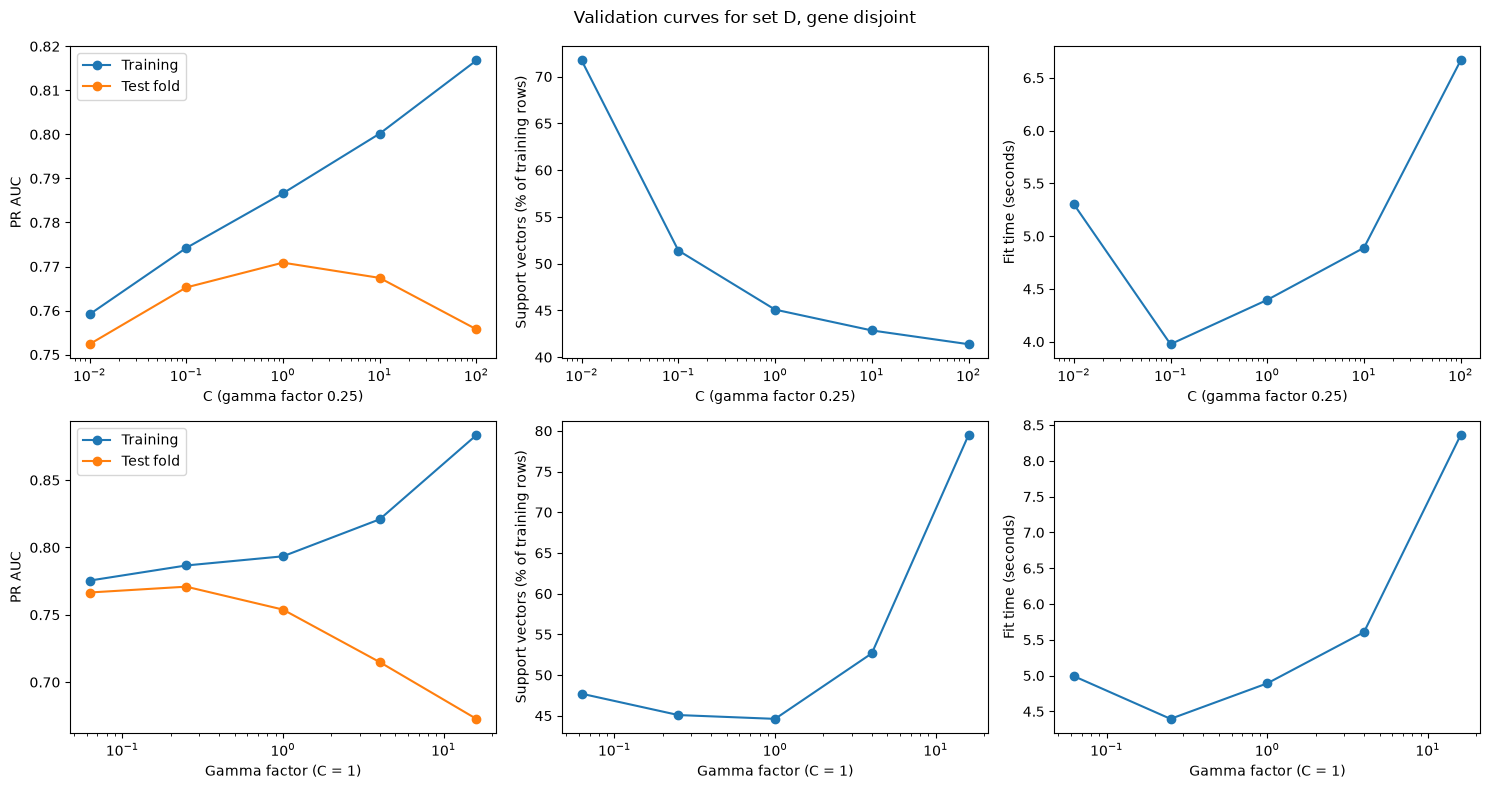

In [20]:
curve_specs = [
    ("C", curves[curves["gamma_factor"] == 0.25], "C (gamma factor 0.25)"),
    ("gamma_factor", curves[curves["C"] == 1], "Gamma factor (C = 1)"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row, (param, part, xlabel) in enumerate(curve_specs):
    mean = part.groupby(param)[["train_pr_auc", "test_pr_auc", "sv_pct", "fit_time"]].mean()
    axes[row, 0].plot(mean.index, mean["train_pr_auc"], "o-", label="Training")
    axes[row, 0].plot(mean.index, mean["test_pr_auc"], "o-", label="Test fold")
    axes[row, 0].set_ylabel("PR AUC")
    axes[row, 0].legend()
    axes[row, 1].plot(mean.index, mean["sv_pct"], "o-")
    axes[row, 1].set_ylabel("Support vectors (% of training rows)")
    axes[row, 2].plot(mean.index, mean["fit_time"], "o-")
    axes[row, 2].set_ylabel("Fit time (seconds)")
    for ax in axes[row]:
        ax.set_xscale("log")
        ax.set_xlabel(xlabel)
plt.suptitle("Validation curves for set D, gene disjoint")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_validation_curves.png", dpi=200)
plt.show()

## 16. Learning curves

A learning curve trains the model on growing parts of the training fold and tracks the score on the training data and on the test fold. If the test score is still rising at the full size, more data would likely help. The gap between the two lines shows how much better the model fits the data it was trained on.

For each set I use the five gene disjoint folds of repeat 0 with the C and gamma chosen for that fold. The training score is computed on a sample of 5,000 training rows to save time.

In [21]:
TRAIN_SIZES = [0.1, 0.25, 0.5, 1.0]


def learning_point(set_name, fold, size):
    X = df[feature_sets[set_name]].to_numpy()
    best = results[
        (results["scheme"] == "gene_disjoint") & (results["set"] == set_name)
        & (results["repeat"] == 0) & (results["fold"] == fold)
    ].iloc[0]

    is_test = folds["gene_disjoint_r0"].to_numpy() == fold
    train_idx, test_idx = np.where(~is_test)[0], np.where(is_test)[0]
    if size < 1:
        train_idx, _ = train_test_split(
            train_idx, train_size=size, stratify=y[train_idx], random_state=SEED
        )

    model = make_model().set_params(svm__C=best["best_C"], svm__gamma=best["best_gamma"])
    start = time.time()
    model.fit(X[train_idx], y[train_idx])
    fit_time = time.time() - start

    score_idx = train_idx
    if len(train_idx) > 5000:
        score_idx = np.random.default_rng(SEED).choice(train_idx, 5000, replace=False)

    return {
        "set": set_name,
        "fold": fold,
        "size": size,
        "n_train": len(train_idx),
        "train_pr_auc": average_precision_score(y[score_idx], model.decision_function(X[score_idx])),
        "test_pr_auc": average_precision_score(y[test_idx], model.decision_function(X[test_idx])),
        "fit_time": fit_time,
    }


learning_file = RESULTS_DIR / "learning_curves.csv"
if learning_file.exists():
    learning = pd.read_csv(learning_file)
else:
    jobs = [(s, k, size) for s in SETS for k in range(N_FOLDS) for size in TRAIN_SIZES]
    learning = pd.DataFrame(
        Parallel(n_jobs=N_JOBS, backend="threading")(delayed(learning_point)(*j) for j in jobs)
    )
    learning.to_csv(learning_file, index=False)

learning_mean = learning.groupby(["set", "size"]).mean(numeric_only=True).drop(columns="fold")
display(learning_mean.round(3))

n_train  train_pr_auc  test_pr_auc  fit_time
set size                                              
A   0.10   3680.6         0.603        0.582     1.398
    0.25   9202.0         0.606        0.587     7.009
    0.50  18404.6         0.597        0.587    27.097
    1.00  36809.6         0.597        0.585   101.683
B   0.10   3680.6         0.718        0.709     0.561
    0.25   9202.0         0.723        0.712     3.277
    0.50  18404.6         0.723        0.713    14.107
    1.00  36809.6         0.724        0.712    64.041
D   0.10   3680.6         0.786        0.762     0.556
    0.25   9202.0         0.792        0.772     3.508
    0.50  18404.6         0.787        0.775    15.582
    1.00  36809.6         0.794        0.780    67.049

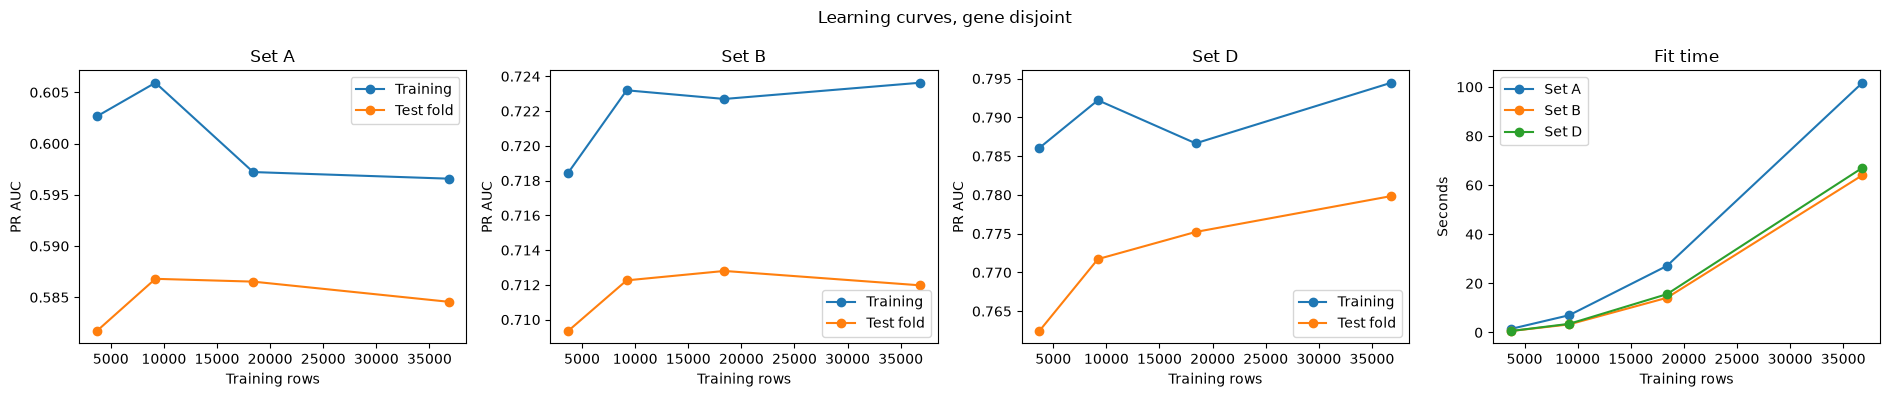

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, set_name in zip(axes, SETS):
    part = learning_mean.loc[set_name]
    ax.plot(part["n_train"], part["train_pr_auc"], "o-", label="Training")
    ax.plot(part["n_train"], part["test_pr_auc"], "o-", label="Test fold")
    ax.set(title=f"Set {set_name}", xlabel="Training rows", ylabel="PR AUC")
    ax.legend()
for set_name in SETS:
    part = learning_mean.loc[set_name]
    axes[3].plot(part["n_train"], part["fit_time"], "o-", label=f"Set {set_name}")
axes[3].set(title="Fit time", xlabel="Training rows", ylabel="Seconds")
axes[3].legend()
plt.suptitle("Learning curves, gene disjoint")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_learning_curves.png", dpi=200)
plt.show()

## 17. Run time and memory

Tune time covers the grid search on the tuning sample. Calibration time is the extra time for Platt scaling. Fit time is for the final model on the full training fold. Several runs share one process, so peak memory is the highest memory used by the whole notebook up to that run. It is an upper bound for a single run. Model size is the size of the saved model, which grows with the number of support vectors.

In [23]:
cost_cols = ["tune_time", "calib_time", "fit_time", "predict_time", "model_mb", "peak_mem_mb"]
cost_table = mean_sd_table(results, cost_cols, digits=1)
cost_table.to_csv(RESULTS_DIR / "table_runtime_memory.csv")
display(cost_table)

total_minutes = results[["tune_time", "calib_time", "fit_time", "predict_time"]].sum().sum() / 60
print(f"Total compute time across all runs: {total_minutes:.1f} minutes")

tune_time     calib_time     fit_time predict_time   model_mb     peak_mem_mb
scheme        set                                                                                  
Standard      A    128.1 (11.8)    122.4 (6.6)   62.1 (5.5)   13.6 (1.4)  1.4 (0.0)   2880.6 (85.6)
              B    136.4 (18.1)    114.2 (6.5)   61.8 (8.9)   15.8 (3.6)  2.6 (0.1)   2880.6 (85.6)
              D     146.3 (5.3)    107.3 (9.6)   61.6 (5.5)   11.4 (1.1)  3.7 (0.1)  3038.6 (146.7)
Gene disjoint A    186.2 (71.0)  231.3 (156.0)  78.7 (28.5)   13.1 (2.2)  1.4 (0.1)  3065.0 (136.6)
              B    144.8 (20.7)   142.3 (27.8)   77.3 (9.9)   16.1 (3.0)  2.6 (0.1)  3065.0 (136.6)
              D    213.8 (42.2)   189.3 (75.1)  83.2 (12.7)   14.4 (3.2)  3.7 (0.1)  3065.0 (136.6)

Total compute time across all runs: 592.9 minutes


## 18. Gain versus cost

This puts the performance gain of each set next to its run time, both compared with set A. Time per run adds the tuning, calibration, final fit and prediction times. Six runs shared the CPU at once, so the times are a little noisy, but the comparison between sets is fair because all sets ran under the same conditions.

In [24]:
summary_cols = ["pr_auc", "mcc", "tune_time", "calib_time", "fit_time", "predict_time", "sv_total_pct"]
set_means = results.groupby(["scheme", "set"])[summary_cols].mean()
set_means["run_time"] = set_means[["tune_time", "calib_time", "fit_time", "predict_time"]].sum(axis=1)

gain_rows = []
for scheme in SCHEMES:
    if scheme not in set_means.index.get_level_values(0):
        continue
    base = set_means.loc[(scheme, "A")]
    for set_name in SETS:
        cur = set_means.loc[(scheme, set_name)]
        gain_rows.append({
            "scheme": SCHEME_NAMES[scheme],
            "set": set_name,
            "pr_auc": cur["pr_auc"],
            "pr_auc_gain": cur["pr_auc"] - base["pr_auc"],
            "mcc_gain": cur["mcc"] - base["mcc"],
            "run_time_s": cur["run_time"],
            "extra_time_pct": 100 * (cur["run_time"] / base["run_time"] - 1),
            "final_fit_s": cur["fit_time"],
            "support_vectors_pct": cur["sv_total_pct"],
        })

gain_cost = pd.DataFrame(gain_rows).set_index(["scheme", "set"])
gain_cost.to_csv(RESULTS_DIR / "table_gain_vs_cost.csv")
display(gain_cost.round(3))

pr_auc  pr_auc_gain  mcc_gain  run_time_s  extra_time_pct  final_fit_s  support_vectors_pct
scheme        set                                                                                             
Standard      A     0.588        0.000     0.000     326.238           0.000       62.102               58.116
              B     0.713        0.125     0.078     328.202           0.602       61.772               52.769
              D     0.782        0.194     0.164     326.532           0.090       61.577               42.962
Gene disjoint A     0.584        0.000     0.000     509.267           0.000       78.709               59.476
              B     0.710        0.126     0.085     380.640         -25.257       77.318               52.972
              D     0.778        0.194     0.168     500.818          -1.659       83.228               42.923

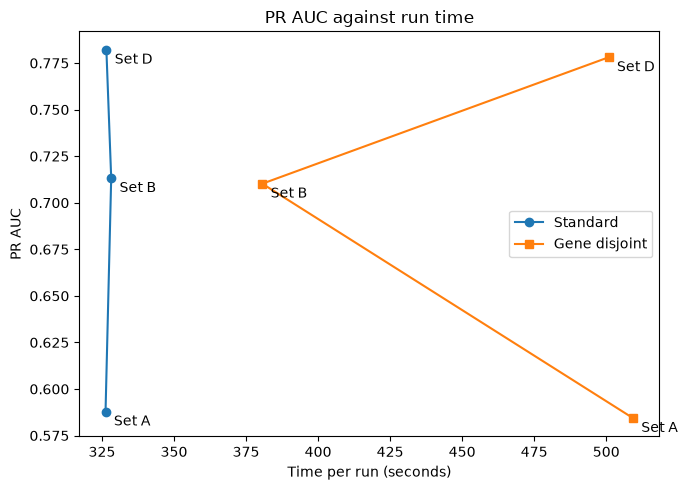

In [25]:
fig, ax = plt.subplots(figsize=(7, 5))
for scheme, marker in zip(SCHEMES, ["o", "s"]):
    part = gain_cost.loc[SCHEME_NAMES[scheme]]
    ax.plot(part["run_time_s"], part["pr_auc"], marker=marker, label=SCHEME_NAMES[scheme])
    for set_name, row in part.iterrows():
        ax.annotate(f"Set {set_name}", (row["run_time_s"], row["pr_auc"]),
                    textcoords="offset points", xytext=(6, -10))
ax.set(xlabel="Time per run (seconds)", ylabel="PR AUC", title="PR AUC against run time")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_gain_vs_cost.png", dpi=200)
plt.show()

## 19. Nystroem approximation

My proposal kept the Nystroem method as a backup in case exact RBF SVM was too slow. It approximates the RBF kernel with a smaller set of landmark points, and then a fast linear SVM is trained on the result. Exact training turned out to be fast enough, but I still check how close the approximation gets, since it would matter for a larger dataset.

This uses set D on the five gene disjoint folds of repeat 0, with the C and gamma chosen for each fold. I try 300, 1,000 and 3,000 landmark points. The exact RBF SVM results for the same folds are shown for comparison. The linear SVM uses a slightly different loss than the exact SVM, so the same C does not mean exactly the same thing in both models. The comparison uses ROC AUC, PR AUC and fit time only, since the Nystroem model is not calibrated. Fit time for the exact SVM does not include calibration.

In [26]:
NYSTROEM_SIZES = [300, 1000, 3000]


def nystroem_point(fold, n_components):
    X = df[feature_sets["D"]].to_numpy()
    best = results[
        (results["scheme"] == "gene_disjoint") & (results["set"] == "D")
        & (results["repeat"] == 0) & (results["fold"] == fold)
    ].iloc[0]

    is_test = folds["gene_disjoint_r0"].to_numpy() == fold
    train_idx, test_idx = np.where(~is_test)[0], np.where(is_test)[0]

    model = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("map", Nystroem(gamma=best["best_gamma"], n_components=n_components, random_state=SEED)),
        ("svm", LinearSVC(C=best["best_C"], class_weight="balanced", dual=False)),
    ])
    start = time.time()
    model.fit(X[train_idx], y[train_idx])
    fit_time = time.time() - start

    score = model.decision_function(X[test_idx])
    pred = (score > 0).astype(int)
    m = get_metrics(y[test_idx], score, pred)
    return {"fold": fold, "landmarks": n_components, "fit_time": fit_time,
            "roc_auc": m["roc_auc"], "pr_auc": m["pr_auc"], "mcc": m["mcc"]}


nystroem_file = RESULTS_DIR / "nystroem_results.csv"
if nystroem_file.exists():
    nystroem = pd.read_csv(nystroem_file)
else:
    jobs = [(k, n) for k in range(N_FOLDS) for n in NYSTROEM_SIZES]
    # Fewer threads here because the larger feature maps use a lot of memory
    nystroem = pd.DataFrame(
        Parallel(n_jobs=3, backend="threading")(delayed(nystroem_point)(*j) for j in jobs)
    )
    nystroem.to_csv(nystroem_file, index=False)

exact = results.query("scheme == 'gene_disjoint' and set == 'D' and repeat == 0")
nys_table = nystroem.groupby("landmarks")[["roc_auc", "pr_auc", "fit_time"]].mean()
nys_table.index = [f"Nystroem, {n} landmarks" for n in nys_table.index]
nys_table.loc["Exact RBF SVM"] = exact[["roc_auc", "pr_auc", "fit_time"]].mean()
nys_table.to_csv(RESULTS_DIR / "table_nystroem.csv")
display(nys_table.round(3))

,roc_auc,pr_auc,fit_time
"Nystroem, 300 landmarks",0.899,0.788,12.766
"Nystroem, 1000 landmarks",0.900,0.791,40.171
"Nystroem, 3000 landmarks",0.901,0.791,1167.536
Exact RBF SVM,0.898,0.780,73.148


## 20. Feature importance

An RBF SVM has no coefficients to read, so I use permutation importance. Each feature is shuffled in the test fold and the drop in PR AUC is recorded. A big drop means the model depends on that feature.

This uses set D on the five gene disjoint folds of repeat 0, so importance is measured on genes the model has never seen. Each model is retrained with the C and gamma chosen for that fold. To keep it quick, each test fold is scored on a sample of 3,000 variants with 3 shuffles per feature.

Features that carry the same information, such as the three gnomAD frequencies, share their importance. A low value therefore does not always mean a feature is useless.

In [27]:
def importance_for_fold(fold):
    cols = feature_sets["D"]
    X = df[cols].to_numpy()
    best = results[
        (results["scheme"] == "gene_disjoint") & (results["set"] == "D")
        & (results["repeat"] == 0) & (results["fold"] == fold)
    ].iloc[0]

    is_test = folds["gene_disjoint_r0"].to_numpy() == fold
    train_idx, test_idx = np.where(~is_test)[0], np.where(is_test)[0]
    test_idx, _ = train_test_split(test_idx, train_size=3000, stratify=y[test_idx], random_state=SEED)

    model = make_model().set_params(svm__C=best["best_C"], svm__gamma=best["best_gamma"])
    model.fit(X[train_idx], y[train_idx])
    perm = permutation_importance(
        model, X[test_idx], y[test_idx], scoring="average_precision", n_repeats=3, random_state=SEED
    )
    return pd.Series(perm.importances_mean, index=cols, name=f"fold_{fold}")


importance_file = RESULTS_DIR / "permutation_importance.csv"
if importance_file.exists():
    importance = pd.read_csv(importance_file, index_col=0)
else:
    parts = Parallel(n_jobs=N_JOBS, backend="threading")(
        delayed(importance_for_fold)(k) for k in range(N_FOLDS)
    )
    importance = pd.concat(parts, axis=1)
    importance.to_csv(importance_file)

group_of = {col: group for group, cols in config["feature_groups"].items() for col in cols}
imp_table = pd.DataFrame({
    "group": importance.index.map(group_of),
    "pr_auc_drop": importance.mean(axis=1),
    "sd": importance.std(axis=1),
}).sort_values("pr_auc_drop", ascending=False)

display(imp_table.round(4))
display(imp_table.groupby("group")["pr_auc_drop"].sum().sort_values(ascending=False).round(4).to_frame("total_drop"))

,group,pr_auc_drop,sd
phyloP100way_vertebrate,conservation,0.1603,0.0194
gnomADg_AF_neglog10,population,0.0765,0.0152
AA_hydropathy_change,amino_acid,0.0722,0.0172
AA_volume_change,amino_acid,0.0621,0.0090
gnomADg_AF_missing,population,0.0507,0.0082
BLOSUM62_score,amino_acid,0.0444,0.0114
AA_mw_change,amino_acid,0.0431,0.0099
AA_charge_change,amino_acid,0.0377,0.0142
gnomAD_AF_neglog10,population,0.0372,0.0169
AA_polarity_change,amino_acid,0.0312,0.0212


,total_drop
group,
amino_acid,0.3635
conservation,0.2146
population,0.1938


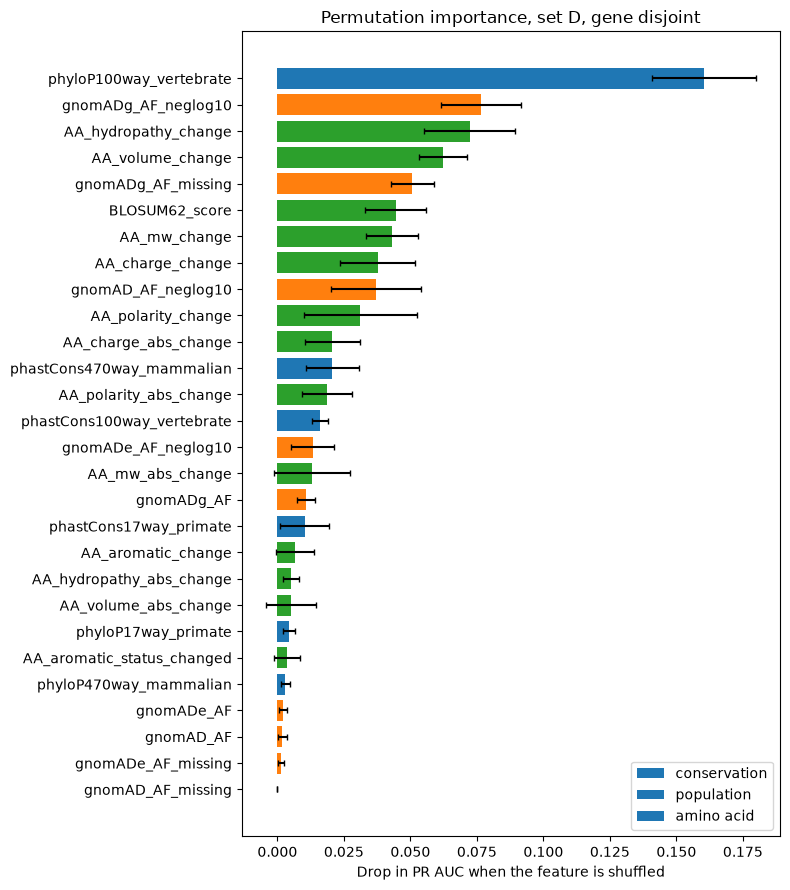

In [28]:
colors = {"conservation": "tab:blue", "population": "tab:orange", "amino_acid": "tab:green"}
plot_data = imp_table.iloc[::-1]

plt.figure(figsize=(8, 9))
plt.barh(plot_data.index, plot_data["pr_auc_drop"], xerr=plot_data["sd"],
         color=plot_data["group"].map(colors), capsize=2)
for group, color in colors.items():
    plt.barh([], [], color=color, label=group.replace("_", " "))
plt.legend(loc="lower right")
plt.xlabel("Drop in PR AUC when the feature is shuffled")
plt.title("Permutation importance, set D, gene disjoint")
plt.tight_layout()
plt.savefig(FIG_DIR / "fig_feature_importance.png", dpi=200)
plt.show()

## 21. Rare variants only

ClinVar curators sometimes label a variant benign because it is common in gnomAD. If so, population frequency partly gives away the label, and set B can look better than it really is. To check this, I recompute the metrics only on rare variants, with a combined gnomAD frequency below 0.0001. If B still beats A here, the gain is less likely to come only from how the labels were assigned.

In [29]:
rare_ids = set(df.loc[df["gnomAD_AF"] < 1e-4, "VariationID"])
rare = df["VariationID"].isin(rare_ids)
print(f"Rare variants: {rare.sum()} ({rare.mean():.1%} of all), pathogenic share {y[rare].mean():.1%}")

rare_rows = []
keys = ["scheme", "set", "repeat", "fold"]
for key, part in preds[preds["VariationID"].isin(rare_ids)].groupby(keys):
    rare_rows.append({**dict(zip(keys, key)), **get_metrics(part["label"], part["p_pathogenic"], part["pred_label"])})

rare_results = pd.DataFrame(rare_rows)
rare_table = mean_sd_table(rare_results, list(METRIC_NAMES))
rare_table.to_csv(RESULTS_DIR / "table_rare_variants.csv")
display(rare_table)

Rare variants: 35284 (76.7% of all), pathogenic share 38.0%


roc_auc         pr_auc            mcc
scheme        set                                             
Standard      A    0.777 (0.005)  0.647 (0.008)  0.432 (0.011)
              B    0.822 (0.003)  0.725 (0.007)  0.475 (0.009)
              D    0.871 (0.004)  0.793 (0.006)  0.572 (0.011)
Gene disjoint A    0.777 (0.012)  0.644 (0.047)  0.421 (0.025)
              B    0.821 (0.012)  0.722 (0.043)  0.473 (0.022)
              D    0.869 (0.008)  0.789 (0.034)  0.564 (0.018)

## 22. Comparison with published tools

As a reference, I score REVEL, CADD, AlphaMissense and ClinPred on the same gene disjoint test folds. These tools need no training here. It is not an equal comparison, since they use much more information than our 28 features, and ClinPred was trained partly on ClinVar labels. Each tool is scored only on variants where it has a value.

In [30]:
tools = ["REVEL_score", "CADD_PHRED_score", "AM_score", "ClinPred_score"]
project = pd.read_csv(
    PREP_DIR / "clinvar_expanded_project_dataset.csv", usecols=["VariationID"] + tools
)
tool_data = folds.merge(project, on="VariationID")

tool_rows = []
for r in range(N_REPEATS):
    for k in range(N_FOLDS):
        test = tool_data[tool_data[f"gene_disjoint_r{r}"] == k]
        for tool in tools:
            part = test.dropna(subset=[tool])
            tool_rows.append({
                "model": tool.replace("_score", ""),
                "coverage_pct": 100 * len(part) / len(test),
                "roc_auc": roc_auc_score(part["label"], part[tool]),
                "pr_auc": average_precision_score(part["label"], part[tool]),
            })

tool_table = pd.DataFrame(tool_rows).groupby("model").mean()
svm_rows = results.query("scheme == 'gene_disjoint'").groupby("set")[["roc_auc", "pr_auc"]].mean()
svm_rows.index = [f"RBF SVM set {n}" for n in svm_rows.index]
svm_rows["coverage_pct"] = 100.0

comparison = pd.concat([svm_rows, tool_table])[["coverage_pct", "roc_auc", "pr_auc"]]
comparison.to_csv(RESULTS_DIR / "table_tool_comparison.csv")
display(comparison.round(3))

,coverage_pct,roc_auc,pr_auc
RBF SVM set A,100.000,0.789,0.584
RBF SVM set B,100.000,0.860,0.710
RBF SVM set D,100.000,0.896,0.778
AM,93.673,0.920,0.840
CADD_PHRED,100.000,0.887,0.754
ClinPred,99.690,0.951,0.899
REVEL,91.631,0.947,0.900


## 23. Findings

These are my observations from the results above. All numbers are means over the 15 test folds unless I say otherwise. All folds come from the team's shared fold file.

**Feature sets and hypotheses**

1. Each feature group adds real information. Under standard validation, PR AUC rises from 0.588 with set A to 0.713 with set B and 0.782 with set D. MCC rises from 0.439 to 0.516 and 0.603.
2. H1 is supported. Adding population frequency improves PR AUC by about 0.125 and MCC by about 0.08. Set B beat set A in all 15 folds under both validation schemes.
3. H2 is supported. On unseen genes, set D beats set A by 0.19 PR AUC and 0.17 MCC, again in all 15 folds. The amino acid features also add about 0.07 PR AUC on top of set B.
4. With 15 folds, 0.00006 is the smallest p value the Wilcoxon test can give, and every comparison reached it. The folds share training data, so I treat this as strong agreement across folds rather than an exact p value.

**Standard versus gene disjoint**

1. Performance on unseen genes is almost the same as under standard validation. The largest drop is 0.004 PR AUC and 0.010 MCC.
2. My reading is that these features describe the variant itself, such as how conserved the position is and how different the new amino acid is, so the model does not depend on having seen other variants from the same gene.
3. Results vary more between folds when genes are held out. For set D the standard deviation of MCC goes from 0.011 to 0.017, and the PR AUC spread is larger too, partly because the share of pathogenic variants differs between gene disjoint folds (from about 25% to 35%).

**Probabilities and the threshold**

1. Platt scaling keeps the order of the decision scores, so ROC AUC and PR AUC are the same as with the raw scores.
2. With the shared threshold of 0.5, the calibrated model labels fewer variants as pathogenic than the raw SVM did. For set D it finds 72.8% of the pathogenic variants and keeps 87.7% of the benign ones. A lower threshold would find more pathogenic variants, but the team agreed on 0.5 so that all models are compared in the same way.

**Model behaviour**

1. The decision boundary gets simpler as features are added. Support vectors fall from about 58% of the training rows with set A to 53% with set B and 43% with set D.
2. The classes also separate more clearly. The share of test variants inside the margin falls from about 49% with set A to 37% with set D.
3. The tuned values differ by set. Set B mostly chose C of 0.1 with the smallest gamma, while set D chose C of 10 in almost every fold. Tuning each set separately, as planned in the proposal, was the right choice.
4. The validation curves show overfitting when gamma is too large. With a gamma factor of 16, the training PR AUC reaches 0.88 while the test PR AUC drops to 0.67. Raising C to 100 also starts to overfit, but more gently.
5. The learning curves are almost flat. Set D goes from 0.762 PR AUC with 10% of the training data to 0.780 with all of it, and the training and test scores stay close. More data of the same kind would help only a little. New kinds of features would help more.

**Cost**

1. A full run of 90 models, with tuning and calibration, took about 94 minutes using 6 threads. Calibration fits the SVM three more times per fold, so it roughly doubled the time compared with the uncalibrated run.
2. Fit time grows much faster than the data. Ten times more training rows made the fit about 100 times slower, which matches what is known about exact SVM training.
3. Under standard validation, set D took almost the same time per run as set A while adding 0.19 PR AUC, so the extra features are worth it. Under gene disjoint validation the run times varied a lot from fold to fold because six runs shared the CPU, so I do not draw conclusions from those times.
4. The Nystroem approximation was not needed, but it works well here. With only 300 landmark points it matched the exact SVM on the same folds (PR AUC 0.788 against 0.780) and trained in about 13 seconds instead of 73. These timings come from runs that shared the CPU, so they are only a rough comparison.

**Which features matter**

1. Vertebrate phyloP is by far the most important single feature. Shuffling it lowers PR AUC by 0.16.
2. The next most important are the gnomAD genome rarity score, hydropathy change, volume change, the gnomAD genome missing flag and BLOSUM62.
3. Summed by group, the amino acid features matter most, then conservation, then population frequency. Features that carry similar information share their importance, so the primate and mammalian conservation scores look smaller partly because vertebrate phyloP already covers them.

**Checks on the result**

1. The population frequency gain is not only label circularity. On rare variants alone, which are 77% of the data, set B still beats set A by about 0.08 PR AUC (0.725 against 0.647).
2. Accuracy alone is misleading here. Set D reaches 83.1% accuracy, but always predicting benign already gives 69.6%. Balanced accuracy is 80.2%.
3. Set D misses about 27% of pathogenic variants at the 0.5 threshold, so it is not accurate enough for clinical use.
4. Published tools score higher, as expected, since they use much more information. On the unseen gene folds REVEL and ClinPred reach about 0.90 PR AUC and AlphaMissense 0.84. My set D (0.78) is slightly above CADD (0.75). ClinPred was partly trained on ClinVar labels, so its score is likely optimistic on this data.

## 24. Saved files

Everything is saved in the `results/rbf_svm` folder:

1. `predictions_rbf_svm.csv`: predictions in the team format (model, feature_set, validation, repeat, fold, VariationID, label, p_pathogenic, pred_label).
2. `svm_fold_results.csv`: one row per run with metrics, tuned values, support vectors, decision scores, run time and memory.
3. `svm_predictions.csv`: decision score, p_pathogenic and predicted label for every test variant in every run.
4. `validation_curves.csv`, `learning_curves.csv`, `permutation_importance.csv` and `nystroem_results.csv`: results of the extra analyses. They are reused when the notebook is run again.
5. `table_*.csv` and `fig_*.png`: the tables and figures shown above.
6. `folds`: the saved result of each single run, used to resume the notebook.